# Oversampling

### <i> Using ADASYN (Adaptive Synthetic Sampling).

<i> ADASYN is designed in mind to generate more hard-to-learn minority samples in your dataset. This works incredibly well for when we need to establish a CLEAR boundary between clusters. </i>

<br>

<strong style='color:orange ; background-color:black;'> WARNING:  Be sure that only little amounts overlap exists in your dataset before trying this </strong>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.datasets import make_blobs
import pandas as pd


# data generated with AI (Claude):
# "Make me two circular-like clusters in a dataframe using
# scikit-learn's make_blobs. One should be a majority cluster, 
# the other should be a minority cluster." --prompt

X_majority, _ = make_blobs(
    n_samples=500,
    centers=[(0, 0)],
    cluster_std=1.2,
    random_state=42
)

X_minority, _ = make_blobs(
    n_samples=100,
    centers=[(3, 3)],
    cluster_std=1.0,
    random_state=42
)

X = np.vstack([X_majority, X_minority])
y = np.hstack([
    np.zeros(len(X_majority)),
    np.ones(len(X_minority))
])

df = pd.DataFrame(X,columns=["measurement_1", "measurement_2"])
df = pd.DataFrame(X, columns=["feature_1", "feature_2"])

df["target"] = y

---

### The problem

<Axes: xlabel='feature_1', ylabel='feature_2'>

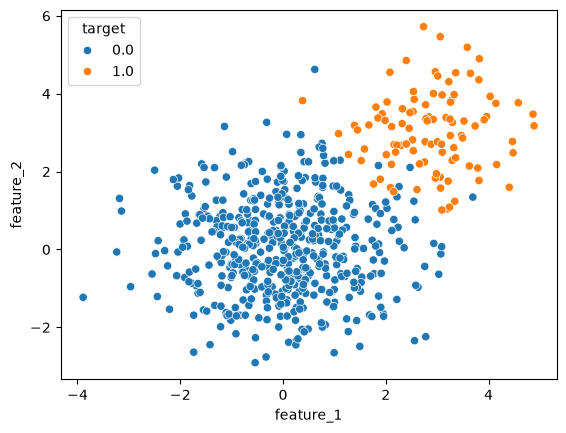

In [8]:
# The features are under-represented here in the minority and it represents a clear overlap boundary. This is a
# perfect use case for `ADASYN`.
sns.scatterplot(df, x="feature_1", y="feature_2", hue="target")

---

### Testing ADASYN -- Example 1

In [9]:
from imblearn.over_sampling import ADASYN

# X, y split
y = df["target"]
X = df.drop("target", axis=1)

# Load `ADASYN`
adasyn = ADASYN(random_state=42)

# Resample X and Y separately
X_oversampled, y_oversampled = adasyn.fit_resample(X, y)

# Recreate the dataframe.
df_oversampled = pd.DataFrame(X_oversampled)
df_oversampled["target"] = y_oversampled


<Axes: xlabel='feature_1', ylabel='feature_2'>

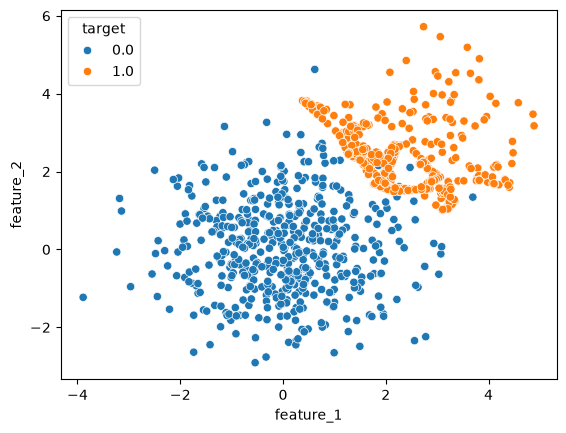

In [10]:
# The features are under-represented here in the minority. This is a
# perfect use case for `ADASYN`.
sns.scatterplot(df_oversampled, x="feature_1", y="feature_2", hue="target")

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<h3>What changed?</h3>

<i>

`ADASYN` now has helped us establish a clear boundary to help ML algorithms figure out these cluster patterns.

Though in this case, it is a bit overkill.

<strong>In a real-case scenario, we would want to lower the amount of boundary examples to be more realistic. </strong>

</div>

---

### Testing ADASYN -- Example 2

<i> In this case, we'll be using the `sampling_strategy` parameter to limit amount of rows it creates.

In [11]:
from imblearn.over_sampling import ADASYN

# X, y split
y = df["target"]
X = df.drop("target", axis=1)

# Load adasyn
adasyn = ADASYN(
    sampling_strategy=0.35,  
    random_state=42
)

X_resampled, y_resampled = adasyn.fit_resample(X, y)

# Resample X and Y separately
X_oversampled, y_oversampled = adasyn.fit_resample(X, y)

df_oversampled = pd.DataFrame(X_oversampled)
df_oversampled["target"] = y_oversampled

<Axes: xlabel='feature_1', ylabel='feature_2'>

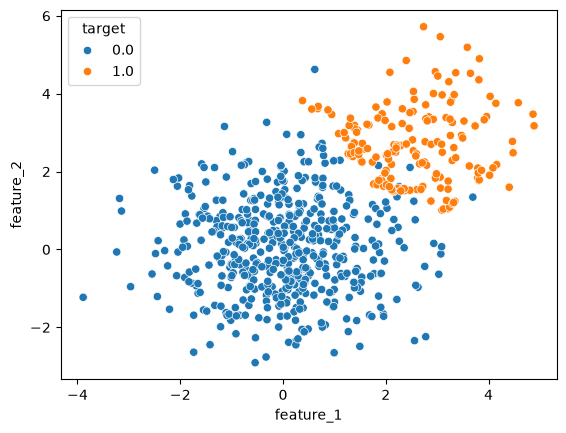

In [12]:
# Much more believable.
sns.scatterplot(df_oversampled, x="feature_1", y="feature_2", hue="target")

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<h3>What changed?</h3>

<i>

This is a much healthier, and more realistic boundary that might be just the push an ML model help accuracy without

breaking the realism of the dataset.


</div>